# **Diabetes Classification Using a Decision Tree**
### Mini Project: Classification Algorithms Exploration



## **1.Introduction**

Diabetes is a common health condition that affects how the body regulates blood sugar levels. Analyzing diabetes-related data can help us understand the factors associated with the condition and explore how machine learning can be used to predict diabetes status.

In this mini-project, we use a **Diabetes Dataset** containing **1,000 records and 14 columns**. The dataset includes different medical and personal characteristics that can help identify patterns related to diabetes.

Our goal is to build a **Decision Tree Classifier** that predicts whether a person belongs to one of three categories based on the target variable `CLASS`:

- **N:** Non-diabetic
- **P:** Pre-diabetic
- **Y:** Diabetic

We begin with **Exploratory Data Analysis (EDA)** to understand the dataset, examine feature distributions, identify patterns, and explore relationships between variables. We then perform **data preprocessing** to handle missing values, clean the data, and prepare the features for machine learning.

After preparing the dataset, we train a **Decision Tree model**, which makes predictions by splitting the data into smaller groups based on feature values. One advantage of this algorithm is that its decision-making process can be visualized and easily interpreted.

Finally, we evaluate the model using **accuracy, precision, recall, F1-score, and a confusion matrix**. We also visualize the Decision Tree and examine feature importance to understand which variables contribute most to its predictions.

Through this project, we aim to gain practical experience in the complete machine learning classification process, from understanding and preparing real-world data to training, evaluating, and interpreting a Decision Tree model.

**Dataset Source:** [Diabetes Dataset — Mendeley Data](https://data.mendeley.com/datasets/wj9rwkp9c2/1)


# **2. Decision Tree Explanation**

A Decision Tree is a classification method that makes a sequence of simple questions about the input data. For example, it can split records according to an age or lab-value threshold. Each split makes the groups more alike in their class. At the end of the branches, called leaves, the tree assigns a class such as `N`, `P`, or `Y`.

A tree is useful here because the target has three categories and the dataset has numeric lab values plus gender. Trees are easy to explain and do not need features to be scaled. A limitation is that a deep tree can memorize the training data, and this dataset has many more `Y` records than `N` or `P`. The later model section should check each class separately and control tree depth.


## **3. Import Libraries & Load Data**


In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_auc_score, roc_curve,ConfusionMatrixDisplay, balanced_accuracy_score
)
from sklearn.preprocessing import label_binarize
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_val_score

sns.set_style("whitegrid")

In [85]:
# Read the CSV and preview the first few records.
df = pd.read_csv("/content/Dataset of Diabetes .csv")
df.head()

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


# **3. Exploratory Data Analysis (EDA)**


## 3.1 First Look at the Data

In [86]:
# Check how many rows and columns are in the file.
df.shape

(1000, 14)

In [87]:
# Review the column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null   int64  
 2   Gender     1000 non-null   object 
 3   AGE        1000 non-null   int64  
 4   Urea       1000 non-null   float64
 5   Cr         1000 non-null   int64  
 6   HbA1c      1000 non-null   float64
 7   Chol       1000 non-null   float64
 8   TG         1000 non-null   float64
 9   HDL        1000 non-null   float64
 10  LDL        1000 non-null   float64
 11  VLDL       1000 non-null   float64
 12  BMI        1000 non-null   float64
 13  CLASS      1000 non-null   object 
dtypes: float64(8), int64(4), object(2)
memory usage: 109.5+ KB


In [88]:
# Count missing values in each column.
df.isnull().sum()

,0
ID,0
No_Pation,0
Gender,0
AGE,0
Urea,0
Cr,0
HbA1c,0
Chol,0
TG,0
HDL,0


In [89]:
# Check for rows that are exact duplicates across all 14 columns.
df.duplicated().sum()

np.int64(0)

In [90]:
# Statistical summary of the numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,1000.0,340.500000,2.403977e+02,1.0,125.75,300.5,550.25,800.00
No_Pation,1000.0,270551.408000,3.380758e+06,123.0,24063.75,34395.5,45384.25,75435657.00
AGE,1000.0,53.528000,8.799241e+00,20.0,51.00,55.0,59.00,79.00
Urea,1000.0,5.124743,2.935165e+00,0.5,3.70,4.6,5.70,38.90
Cr,1000.0,68.943000,5.998475e+01,6.0,48.00,60.0,73.00,800.00
HbA1c,1000.0,8.281160,2.534003e+00,0.9,6.50,8.0,10.20,16.00
Chol,1000.0,4.862820,1.301738e+00,0.0,4.00,4.8,5.60,10.30
TG,1000.0,2.349610,1.401176e+00,0.3,1.50,2.0,2.90,13.80
HDL,1000.0,1.204750,6.604136e-01,0.2,0.90,1.1,1.30,9.90
LDL,1000.0,2.609790,1.115102e+00,0.3,1.80,2.5,3.30,9.90


## 3.2 Check data quality



In [91]:
# Unique values of the categorical columns
print(df["Gender"].value_counts())
print()
print(df["CLASS"].value_counts())

Gender
M    565
F    434
f      1
Name: count, dtype: int64

CLASS
Y     840
N     102
P      53
Y       4
N       1
Name: count, dtype: int64


In [92]:
# Check whether the two identifier columns are unique.
print("ID unique values:       ", df["ID"].nunique(), "out of", len(df))
print("No_Pation unique values:", df["No_Pation"].nunique(), "out of", len(df))

ID unique values:        800 out of 1000
No_Pation unique values: 961 out of 1000


**Problems found to fix before plotting:**

- `Gender` contains both `F` and lowercase `f`.
- `CLASS` contains some labels with extra spaces.
- `ID` and `No_Pation` identify records or patients; they are not health measurements to use as model features.


## 3.3 Data Cleaning

In [93]:
# Standardize the text labels, then rename a few columns to make them easier to read.

# Fix inconsistent labels
df["Gender"] = df["Gender"].str.strip().str.upper()
df["CLASS"] = df["CLASS"].str.strip().str.upper()

# Clear column names
df = df.rename(columns={
    "No_Pation": "Patient_No",
    "AGE": "Age",
    "Cr": "Creatinine",
    "Chol": "Cholesterol",
    "TG": "Triglycerides",
    "CLASS": "Diabetes_Class"
})

print(df["Gender"].value_counts())
print()
print(df["Diabetes_Class"].value_counts())
df.head()

Gender
M    565
F    435
Name: count, dtype: int64

Diabetes_Class
Y    844
N    103
P     53
Name: count, dtype: int64


,ID,Patient_No,Gender,Age,Urea,Creatinine,HbA1c,Cholesterol,Triglycerides,HDL,LDL,VLDL,BMI,Diabetes_Class
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


### Column guide

- `ID`, `Patient_No`: identifiers, excluded from the features
- `Gender`: gender label (`M` or `F`)
- `Age`: age in years
- `Urea`, `Creatinine`: blood test measurements
- `HbA1c`: a blood sugar measurement
- `Cholesterol`, `Triglycerides`, `HDL`, `LDL`, `VLDL`: lipid measurements
- `BMI`: body mass index
- `Diabetes_Class`: target class (`N`, `P`, or `Y`)


## 3.4 Data Visualization

### 3.4.1 Distribution of the numeric columns

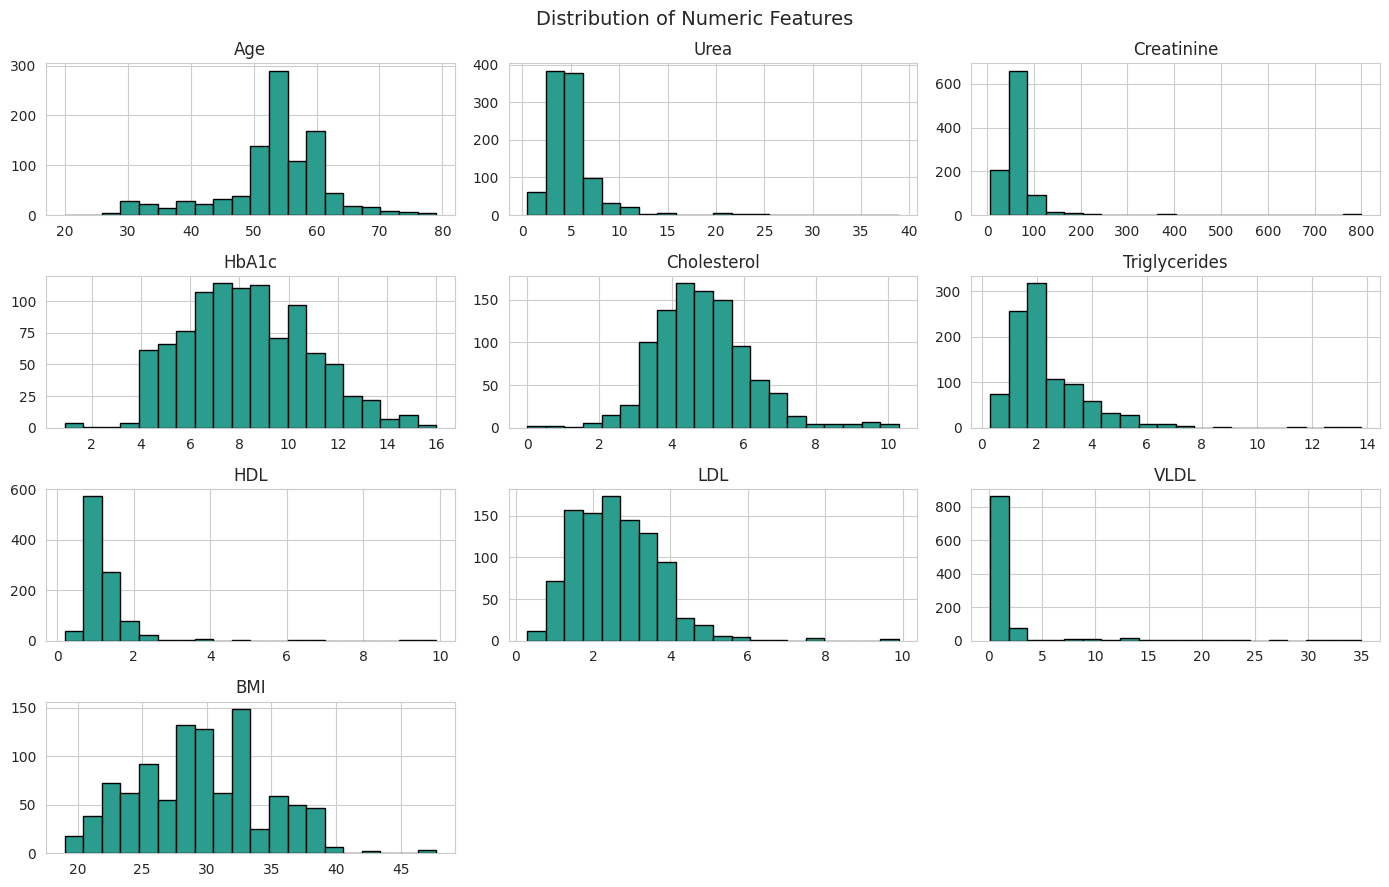

In [94]:
# Plot the distributions of the numeric measurements.
numeric_cols = ["Age", "Urea", "Creatinine", "HbA1c", "Cholesterol",
                "Triglycerides", "HDL", "LDL", "VLDL", "BMI"]

df[numeric_cols].hist(figsize=(14, 9), bins=20, color="#2A9D8F" , edgecolor="black")
plt.suptitle("Distribution of Numeric Features", fontsize=14)
plt.tight_layout()
plt.show()

In [95]:
# Skewness of each feature (values far from 0 = skewed)
df[numeric_cols].skew().round(2).sort_values(ascending=False)

,0
Creatinine,8.47
HDL,6.28
VLDL,5.35
Urea,4.30
Triglycerides,2.30
LDL,1.15
Cholesterol,0.62
HbA1c,0.22
BMI,0.13
Age,-0.82


### 3.4.2 Possible outliers

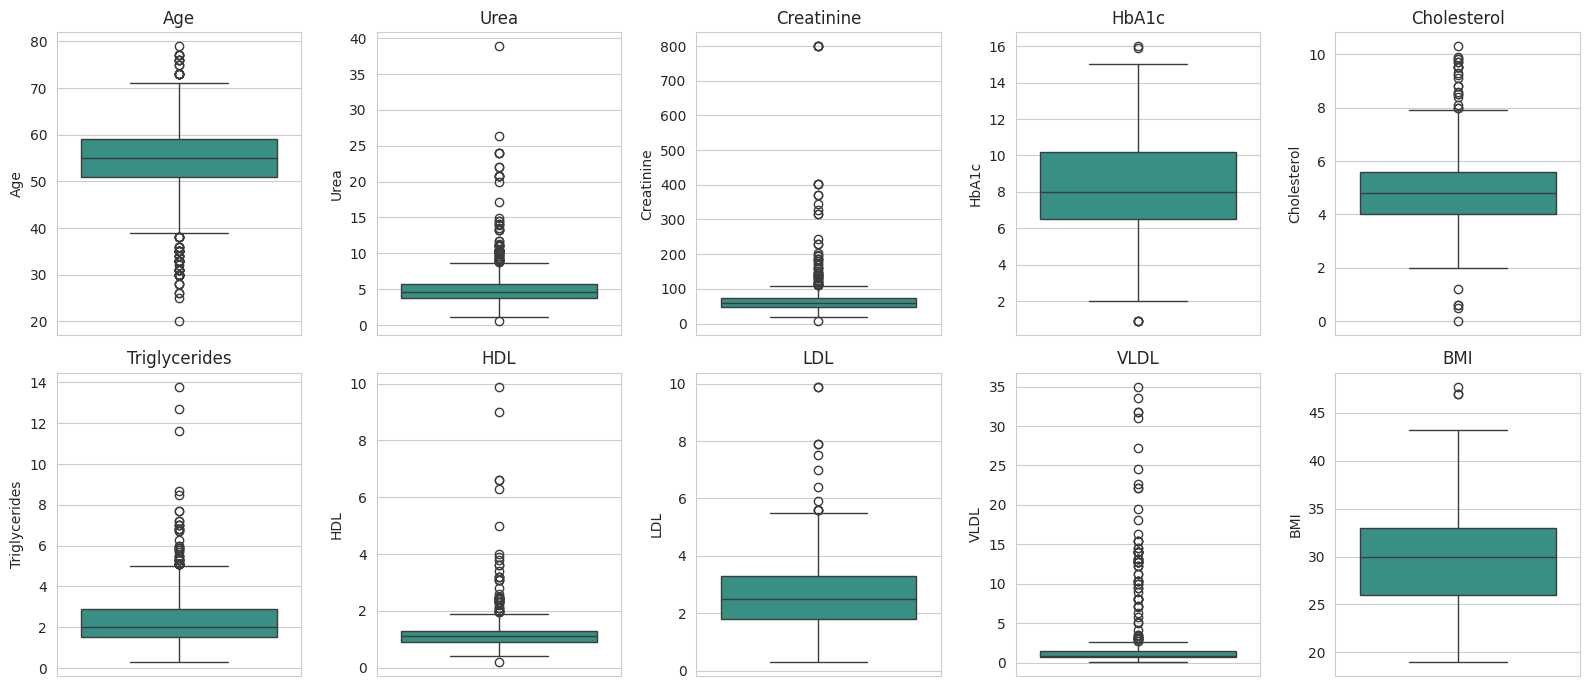

In [96]:
#Use boxplots to look for unusually high or low values.

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="#2A9D8F")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [97]:
# Count possible outliers with the IQR rule. These are flags to inspect, not automatic errors.
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()

    print(col, outliers.sum())

Age 98
Urea 65
Creatinine 52
HbA1c 6
Cholesterol 27
Triglycerides 55
HDL 50
LDL 11
VLDL 74
BMI 3


In [98]:
# Suspicious / extreme values
# Check the zero cholesterol value and the largest kidney-test values.

print((df["Cholesterol"] == 0).sum())
print(df[["Creatinine", "VLDL", "Urea"]].max())

1
Creatinine    800.0
VLDL           35.0
Urea           38.9
dtype: float64


### 3.4.3 Target distribution (class balance)


In [99]:
# Count each diabetes class and show its share of the dataset.
print(df["Diabetes_Class"].value_counts())

print((df["Diabetes_Class"].value_counts(normalize=True) * 100).round(1))

Diabetes_Class
Y    844
N    103
P     53
Name: count, dtype: int64
Diabetes_Class
Y    84.4
N    10.3
P     5.3
Name: proportion, dtype: float64


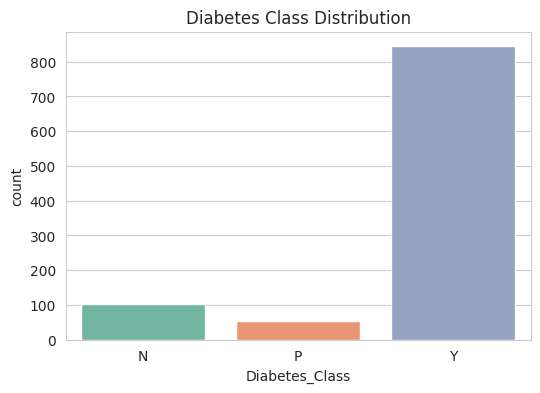

In [100]:
# Plot the number of records in each diabetes class.
plt.figure(figsize=(6, 4))
sns.countplot(x="Diabetes_Class", hue="Diabetes_Class", data=df, order=["N", "P", "Y"], palette="Set2", legend=False)
plt.title("Diabetes Class Distribution")
plt.show()

## 3.4.4 Relationships Between Features

#### Gender VS diabetes class


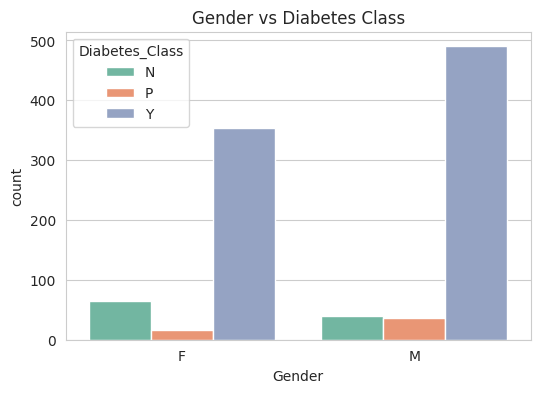

In [101]:
# Compare diabetes class counts by gender.

plt.figure(figsize=(6, 4))
sns.countplot(x="Gender", hue="Diabetes_Class", data=df, hue_order=["N", "P", "Y"], palette="Set2")
plt.title("Gender vs Diabetes Class")
plt.show()

In [102]:
# Show the exact gender-by-class counts in a table
pd.crosstab(df["Gender"], df["Diabetes_Class"])

Diabetes_Class,N,P,Y
Gender,,,
F,64,17,354
M,39,36,490


In [103]:
# Show class percentages within each gender group.
(pd.crosstab(df["Gender"], df["Diabetes_Class"], normalize="index") * 100).round(1)

Diabetes_Class,N,P,Y
Gender,,,
F,14.7,3.9,81.4
M,6.9,6.4,86.7


#### Age VS diabetes class


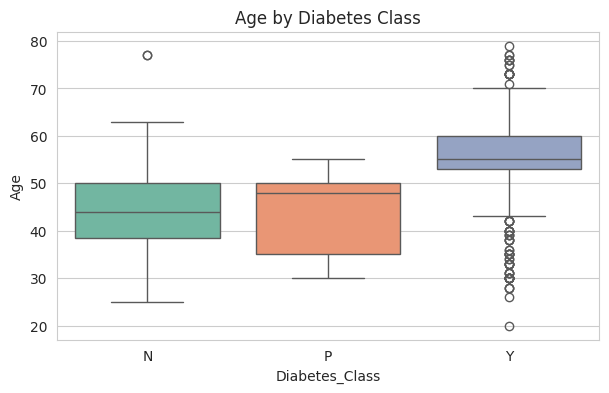

In [104]:
# Compare age across the three diabetes classes.
plt.figure(figsize=(7, 4))
sns.boxplot(x="Diabetes_Class", y="Age", hue="Diabetes_Class", data=df, order=["N", "P", "Y"], palette="Set2", legend=False)
plt.title("Age by Diabetes Class")
plt.show()

#### Lab measurements VS diabetes class


In [105]:
# Average of every feature for each class
df.groupby("Diabetes_Class")[numeric_cols].mean().round(2)

,Age,Urea,Creatinine,HbA1c,Cholesterol,Triglycerides,HDL,LDL,VLDL,BMI
Diabetes_Class,,,,,,,,,,
N,44.23,4.68,62.80,4.56,4.27,1.63,1.23,2.63,0.94,22.37
P,43.28,4.51,66.08,6.00,4.58,2.13,1.13,2.49,0.98,23.93
Y,55.31,5.22,69.87,8.88,4.95,2.45,1.21,2.62,2.02,30.81


In [106]:
# Look at the range and average of HbA1c in each class.
df.groupby("Diabetes_Class")["HbA1c"].agg(["min", "mean", "max"]).round(2)

,min,mean,max
Diabetes_Class,,,
N,0.9,4.56,5.6
P,5.7,6.00,6.4
Y,2.0,8.88,16.0


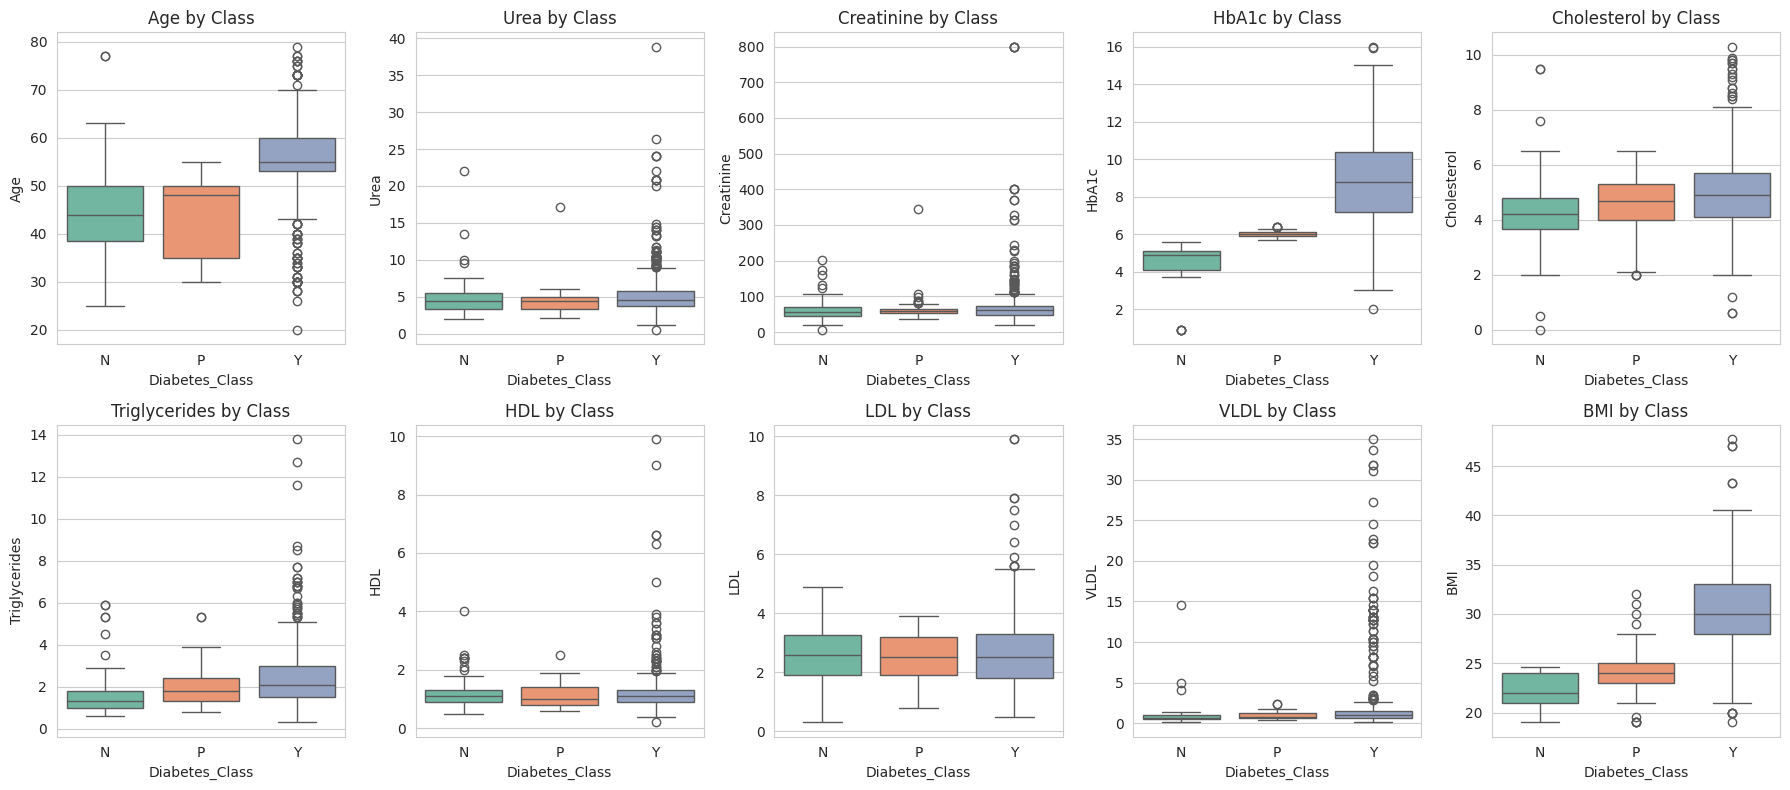

In [107]:
# Compare the distributions of the numeric measurements across classes.
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(x="Diabetes_Class", y=col, hue="Diabetes_Class", data=df, order=["N", "P", "Y"], palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} by Class")
plt.tight_layout()
plt.show()

#### Relationships between measurements


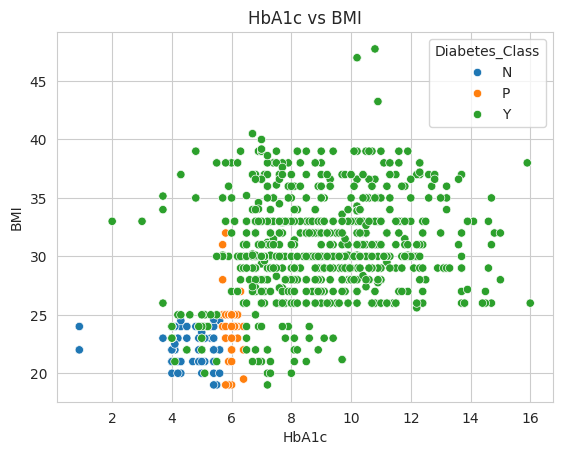

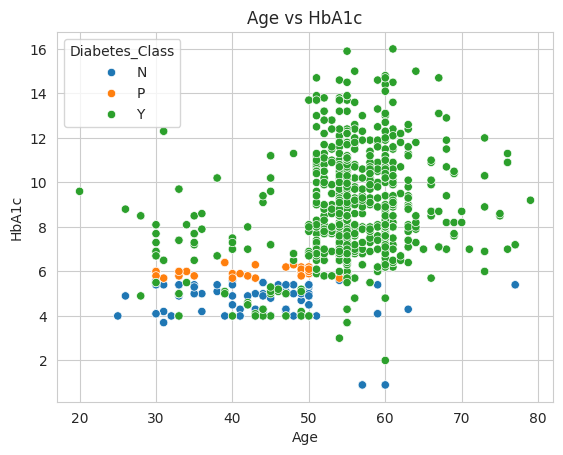

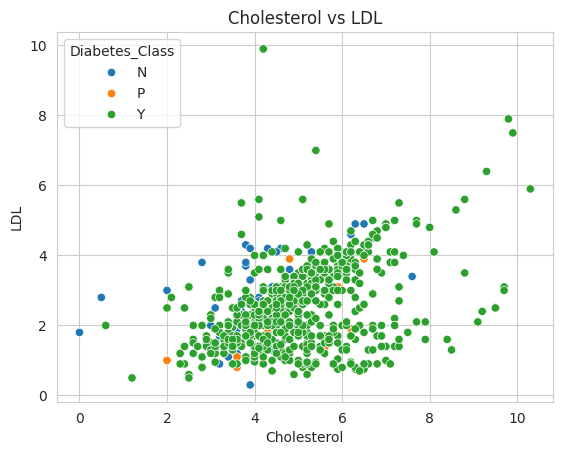

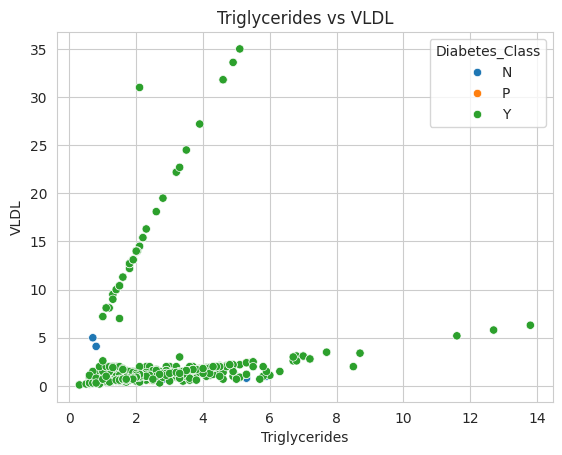

In [108]:
# Plot a few pairs of measurements, colored by diabetes class.

sns.scatterplot(data=df, x="HbA1c", y="BMI", hue="Diabetes_Class")
plt.title("HbA1c vs BMI")
plt.show()

sns.scatterplot(data=df, x="Age", y="HbA1c", hue="Diabetes_Class")
plt.title("Age vs HbA1c")
plt.show()

sns.scatterplot(data=df, x="Cholesterol", y="LDL", hue="Diabetes_Class")
plt.title("Cholesterol vs LDL")
plt.show()

sns.scatterplot(data=df, x="Triglycerides", y="VLDL", hue="Diabetes_Class")
plt.title("Triglycerides vs VLDL")
plt.show()

In [109]:
# Correlation of the pairs shown above

print("HbA1c vs BMI")
print(df[["HbA1c", "BMI"]].corr())
print()

print("Age vs HbA1c")
print(df[["Age", "HbA1c"]].corr())
print()

print("Cholesterol vs LDL")
print(df[["Cholesterol", "LDL"]].corr())
print()

print("Triglycerides vs VLDL")
print(df[["Triglycerides", "VLDL"]].corr())
print()

print("Urea vs Creatinine")
print(df[["Urea", "Creatinine"]].corr())

HbA1c vs BMI
         HbA1c      BMI
HbA1c  1.00000  0.41335
BMI    0.41335  1.00000

Age vs HbA1c
            Age     HbA1c
Age    1.000000  0.379136
HbA1c  0.379136  1.000000

Cholesterol vs LDL
             Cholesterol       LDL
Cholesterol     1.000000  0.416665
LDL             0.416665  1.000000

Triglycerides vs VLDL
               Triglycerides     VLDL
Triglycerides        1.00000  0.14457
VLDL                 0.14457  1.00000

Urea vs Creatinine
                Urea  Creatinine
Urea        1.000000    0.624134
Creatinine  0.624134    1.000000


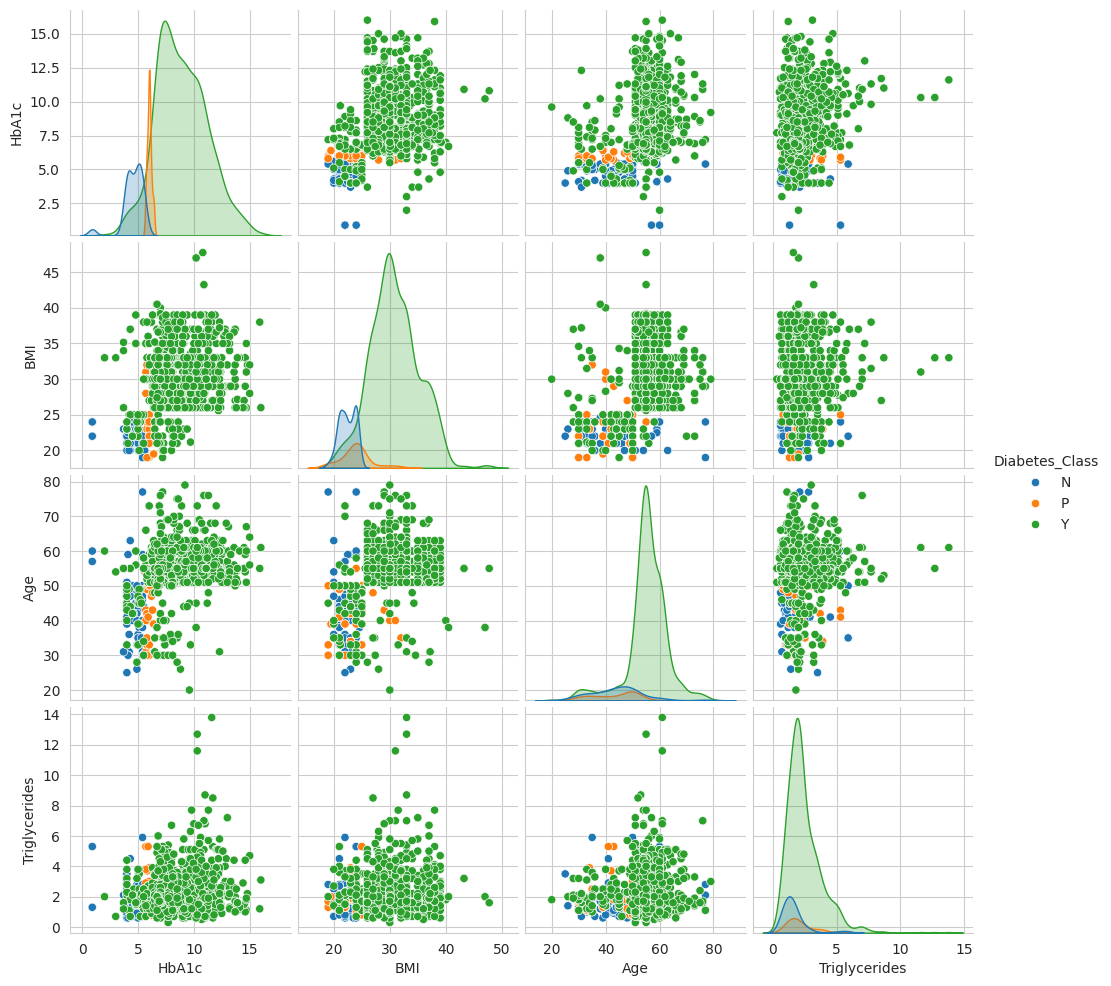

In [68]:
# Pairplot of the most important features
sns.pairplot(df, vars=["HbA1c", "BMI", "Age", "Triglycerides"],
             hue="Diabetes_Class")
plt.show()

## Correlation heatmap


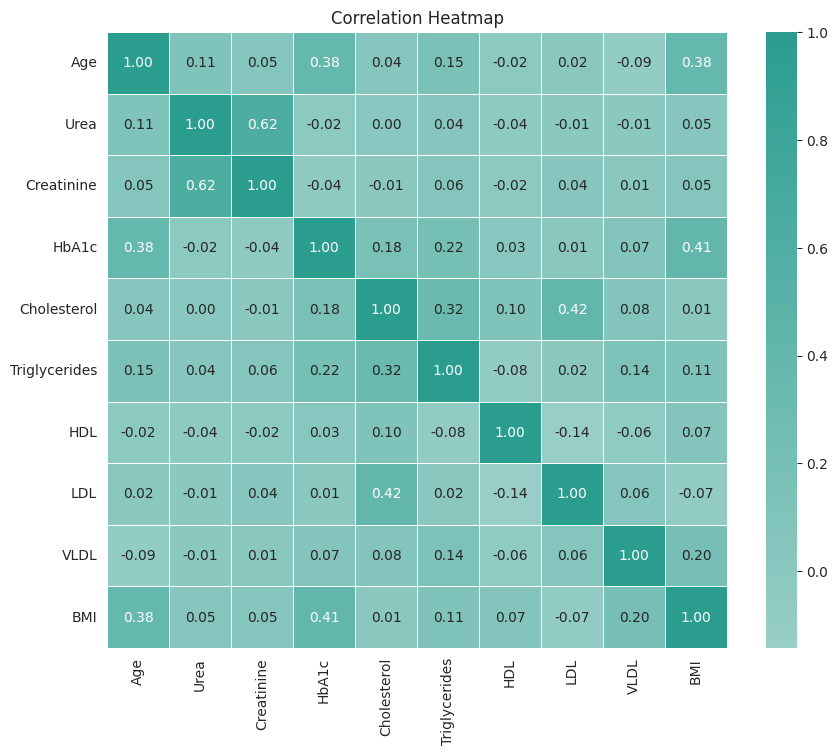

In [69]:
# View correlations among the numeric features in a heatmap.

plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f",  cmap=sns.light_palette("#2A9D8F", as_cmap=True),
    linewidths=0.5,
    linecolor="white", center=0)
plt.title("Correlation Heatmap")
plt.show()


## 3.5 EDA Insights and Findings

**Data quality**
- The data has no missing values, but it was not fully clean: Gender had a lowercase f, and CLASS had labels with trailing spaces ('Y ', 'N '). Both were fixed.
- ID and No_Pation are identifiers, not medical features, so they are excluded from modeling.
- 174 rows are exact duplicates once the identifiers are removed (different patients with identical lab values), so they are removed in preprocessing to avoid train/test leakage.
- Some columns have extreme values (Creatinine up to 800, VLDL up to 35, Urea up to 38.9) and skewed distributions (Creatinine, HDL, VLDL, Urea). One row has Cholesterol = 0, which is not possible, so it is removed.

**Target**
- The classes are **highly imbalanced**: Diabetic (Y) is 84.4%, Non-diabetic (N) 10.3%, Pre-diabetic (P) only 5.3%. Accuracy alone will be misleading, so stratify=y is used in the split and precision/recall per class should be checked after training.

**Relationships**
- **HbA1c is by far the strongest separator**: mean 4.56 for N, 6.00 for P, 8.88 for Y. The ranges of N (up to 5.6) and P (5.7–6.4) do not overlap at all, which matches the medical thresholds. A tree will mostly split on it.
- **BMI** is clearly higher in diabetic patients (30.8 vs 22.4 for N), and **Age** too (55.3 vs 44.2 for N). Older and heavier patients are more likely to be diabetic. HbA1c is moderately correlated with BMI (0.41) and Age (0.38).
- **Triglycerides** and **VLDL** are higher in the diabetic group; **Cholesterol, HDL, LDL, Urea and Creatinine** are very similar across the classes, so they are weak predictors on their own.
- **Gender**: the share of N is higher among females (14.7% vs 6.9%), while males have more P (6.4% vs 3.9%) and Y (86.7% vs 81.4%) cases.
- Feature-to-feature correlations are mostly low-to-moderate. The strongest ones are Urea vs Creatinine (0.62, both kidney tests) and Cholesterol vs LDL (0.42), so there is no serious multicollinearity.

**What this means for modeling**
- HbA1c is very close to defining the class (the label is essentially based on it), so very high accuracy is expected from a Decision Tree.
- Skewed features and outliers are not a problem for a Decision Tree, and it does not need feature scaling.

# **4. Data Preprocessing**


## 4.1 Handling missing values


In [70]:
# Check missing values again before preparing the data.
df.isnull().sum()

,0
ID,0
Patient_No,0
Gender,0
Age,0
Urea,0
Creatinine,0
HbA1c,0
Cholesterol,0
Triglycerides,0
HDL,0


In [71]:
# No NaN values, but zeros can hide missing values in medical data check them
(df[numeric_cols] == 0).sum()

,0
Age,0
Urea,0
Creatinine,0
HbA1c,0
Cholesterol,1
Triglycerides,0
HDL,0
LDL,0
VLDL,0
BMI,0


There are **no missing values**. The only invalid-looking value is `Cholesterol = 0` (impossible in a living patient), so we look at those rows before deciding.

In [72]:
# Inspect the record with a zero cholesterol value before deciding how to handle it.
df[df["Cholesterol"] == 0]

,ID,Patient_No,Gender,Age,Urea,Creatinine,HbA1c,Cholesterol,Triglycerides,HDL,LDL,VLDL,BMI,Diabetes_Class
99,186,454316,M,77,5.0,106,5.4,0.0,2.8,0.8,1.8,0.7,19.0,N


## 4.2 Remove identifiers and repeated profiles


`ID` and `Patient_No` are not health measurements, so they should not be model features. Once they are removed, 174 repeated rows remain across the medical fields and target. I remove those repeated profiles in the prepared copy to avoid identical records appearing in both parts of a later model split.


In [73]:
# Remove the identifier columns, then count and remove repeated medical profiles.

df = df.drop(columns=["ID", "Patient_No"])
df = df.drop_duplicates().reset_index(drop=True)

print(df.shape)
print(df["Diabetes_Class"].value_counts())

(826, 12)
Diabetes_Class
Y    690
N     96
P     40
Name: count, dtype: int64


## 4.3 Decide what to do with outliers


Outliers (e.g. very high Creatinine) are real medical values in most cases, and Decision Trees are not sensitive to outliers (they split on thresholds, not on distances), so we keep them.

In [74]:
# Remove the one zero-cholesterol record flagged above and check the resulting data size.

df = df[df["Cholesterol"] > 0]

print((df["Cholesterol"] == 0).sum())
print(df.shape)

0
(825, 12)


## 4.4 Encode the categories


Gender is converted to a 0/1 column. The target labels are encoded as numbers so they are ready for the later classifier.


In [75]:
# Separate the features from the target and encode gender and diabetes class for later modeling.

# Features and target
X = df.drop(columns=["Diabetes_Class"])
y = df["Diabetes_Class"]

# Encode Gender
X = pd.get_dummies(X, columns=["Gender"], drop_first=True, dtype=int)

# Encode the target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Target mapping:", {c: int(i) for i, c in enumerate(le.classes_)})
X.head()

Target mapping: {'N': 0, 'P': 1, 'Y': 2}


,Age,Urea,Creatinine,HbA1c,Cholesterol,Triglycerides,HDL,LDL,VLDL,BMI,Gender_M
0,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,0
1,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,1
2,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,1
3,45,2.3,24,4.0,2.9,1.0,1.0,1.5,0.4,21.0,0
4,50,2.0,50,4.0,3.6,1.3,0.9,2.1,0.6,24.0,0


### Preprocessing summary

- Standardized `Gender` and `CLASS` labels and renamed columns for readability.
- Found no blank values to fill.
- Dropped `ID` and `Patient_No` from the model features.
- Removed 174 repeated medical profiles and one record with cholesterol equal to zero.
- Kept the other IQR outliers and did not scale numeric features.
- Encoded gender and the target. The prepared data has 825 rows and is ready for the later modeling section.


# **5. Model Implementation**

## 5.1 Train/Test Split

In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 5.2 Baseline Model: Logistic Regression

In [77]:
# Training logistic Regression model as our baseline
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)

# Baseline Model Evaluation
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred,average='macro', zero_division=0))
print("Recall:", recall_score(y_test, y_pred,average='macro', zero_division=0))
print("F1:", f1_score(y_test, y_pred,average='macro', zero_division=0))

print("\nClassification report:\n", classification_report(y_test, y_pred, zero_division=0))

Confusion matrix:
 [[ 17   0   2]
 [  1   2   5]
 [  1   1 136]]

Accuracy: 0.9393939393939394
Precision: 0.8374841532736269
Recall: 0.7100813628273582
F1: 0.7421149119969123

Classification report:
               precision    recall  f1-score   support

           N       0.89      0.89      0.89        19
           P       0.67      0.25      0.36         8
           Y       0.95      0.99      0.97       138

    accuracy                           0.94       165
   macro avg       0.84      0.71      0.74       165
weighted avg       0.93      0.94      0.93       165



## 5.3 Decision Tree Model

In [112]:
# Training Decision Tree model on different depths using cross-validation
results = []
for depth in range(1, 11):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1_macro"
    )

    results.append({"Depth": depth,"Mean CV F1": scores.mean()})

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Depth,Mean CV F1
0,1,0.534
1,2,0.768
2,3,0.866
3,4,0.926
4,5,0.947
5,6,0.936
6,7,0.917
7,8,0.921
8,9,0.921
9,10,0.921


comparing Decision Trees with different maximum depths (1–10) to understand how tree complexity affects model performance.

Accuracy measures overall correct predictions, but it can be misleading because our diabetes dataset is imbalanced.

Macro F1-score balances precision and recall while giving equal importance to all three diabetes classes.

Macro Recall helps us understand how well the model identifies each class, especially pre-diabetic (P) and diabetic (Y) cases.

Depth 5 was selected as our preferred model because it provided a good balance between classification performance and model simplicity, while reducing the risk of overfitting.

In [114]:
# Using  depth = 5 as our model

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

# Decision Tree Evaluation
print("Confusion matrix:\n", confusion_matrix(y_test, tree_pred))
print("\nAccuracy:", accuracy_score(y_test, tree_pred))
print("Precision:", precision_score(y_test, tree_pred,average='macro', zero_division=0))
print("Recall:", recall_score(y_test, tree_pred,average='macro', zero_division=0))
print("F1:", f1_score(y_test, tree_pred,average='macro', zero_division=0))

print("\nClassification report:\n", classification_report(y_test, tree_pred, zero_division=0))

Confusion matrix:
 [[ 17   0   2]
 [  0   8   0]
 [  0   0 138]]

Accuracy: 0.9878787878787879
Precision: 0.9952380952380953
Recall: 0.9649122807017544
F1: 0.9790833999467093

Classification report:
               precision    recall  f1-score   support

           N       1.00      0.89      0.94        19
           P       1.00      1.00      1.00         8
           Y       0.99      1.00      0.99       138

    accuracy                           0.99       165
   macro avg       1.00      0.96      0.98       165
weighted avg       0.99      0.99      0.99       165



## 5.4 ROC-AUC

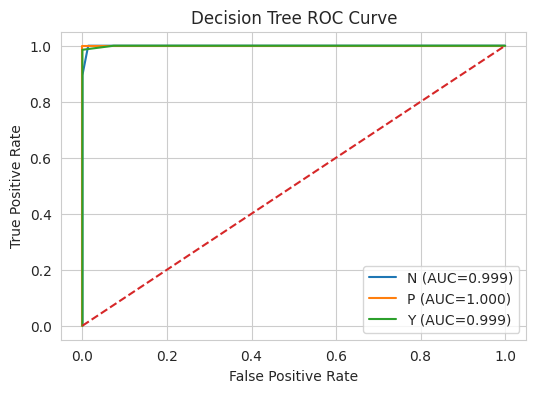

In [115]:
tree_prob = tree.predict_proba(X_test)
y_test_bin = label_binarize(y_test, classes=tree.classes_)
plt.figure(figsize=(6,4))
for i in range(len(tree.classes_)):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], tree_prob[:, i])
    auc = roc_auc_score(y_test_bin[:, i], tree_prob[:, i])
    plt.plot(fpr, tpr, label=f"{le.classes_[i]} (AUC={auc:.3f})")

plt.plot([0,1], [0,1], linestyle="--")
plt.title("Decision Tree ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## Decision Tree Visualizatio

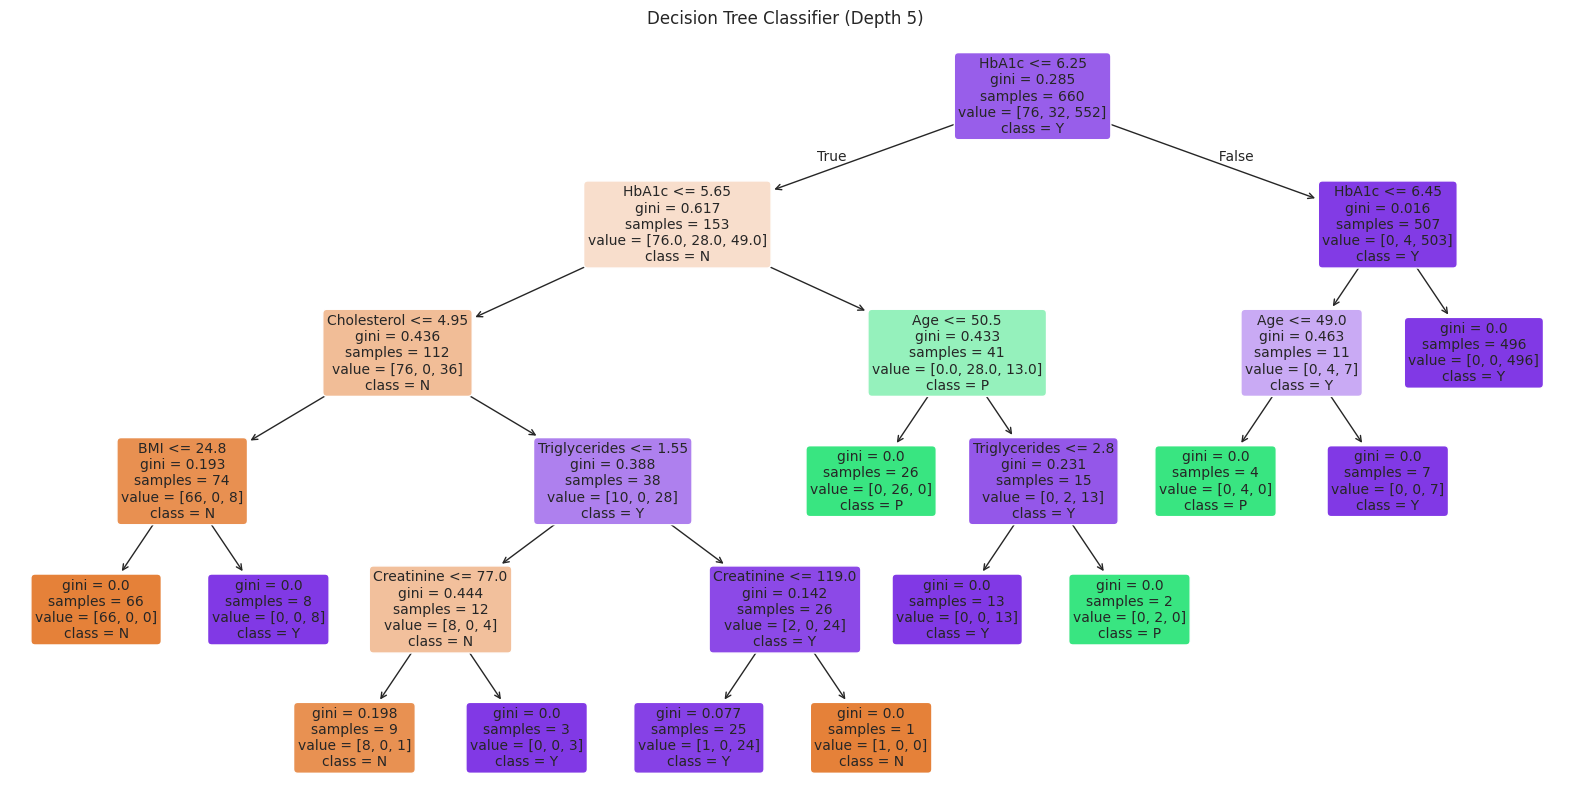

In [118]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["N", "P", "Y"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier (Depth 5)")
plt.show()

The Decision Tree plot shows how the model makes decisions step by step using the input features. Each node represents a condition on a feature, and each branch leads to a further split until a final class is predicted. Since the selected depth 5, the tree remains simple enough to interpret while still giving good performance. The upper splits are the most important because they have the biggest role in separating the diabetes classes.

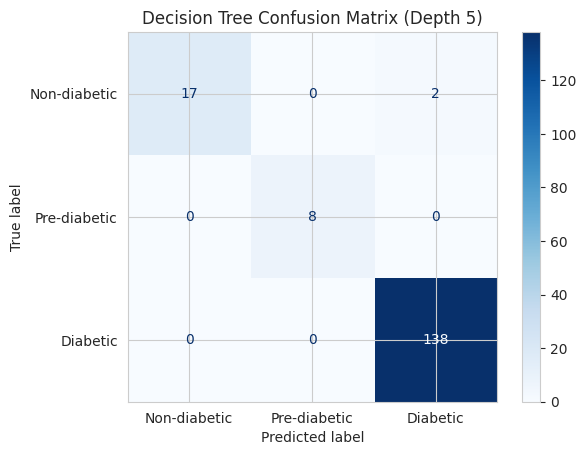

In [119]:
from sklearn.metrics import ConfusionMatrixDisplay

# Predictions using the selected Decision Tree (Depth 5)
y_pred = tree.predict(X_test)

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["N", "P", "Y"],
    display_labels=["Non-diabetic", "Pre-diabetic", "Diabetic"],
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree Confusion Matrix (Depth 5)")
plt.show()

## 6. Conclusion

In this mini-project, we explored how a Decision Tree Classifier can predict diabetes status across three classes: Non-diabetic, Pre-diabetic, and Diabetic.

We compared Decision Trees with different maximum depths using 5-fold cross-validation and selected **Depth 5**, which achieved the highest mean Macro F1-score of **94.7%**.

On the test set, our Decision Tree achieved **98.8% accuracy and 97.9% Macro F1-score**, outperforming the Logistic Regression baseline, which achieved 93.9% accuracy and 74.2% Macro F1-score.

The confusion matrix showed only two incorrect predictions out of 165 test samples, while the ROC-AUC results indicated strong classification performance across all three classes.

Overall, this project helped us understand the complete classification workflow, from data exploration and preprocessing to model training, evaluation, and interpretation. Future improvements could include using Feature Importance to identify which features contribute most to the model's predictions, and testing the model on an independent dataset to evaluate its generalization performance.